Connected to Python 3.12.10

In [ ]:
import pandas as pd
import numpy as np
import os

# طباعة المسار الحالي للتأكد
print("Current Working Directory:", os.getcwd())

# قراءة الملفات مباشرة (إذا كانت الملفات في نفس المجلد المفتوح)
orders = pd.read_csv('orders.csv')
print(orders.head())

Current Working Directory: c:\Users\DELL\Downloads\Compressed\archive_10
   order_id  user_id eval_set  order_number  order_dow  order_hour_of_day  \
0   2539329        1    prior             1          2                  8   
1   2398795        1    prior             2          3                  7   
2    473747        1    prior             3          3                 12   
3   2254736        1    prior             4          4                  7   
4    431534        1    prior             5          4                 15   

   days_since_prior_order  
0                     NaN  
1                    15.0  
2                    21.0  
3                    29.0  
4                    28.0  


In [ ]:
import pandas as pd
import os

print("Files in directory:", os.listdir('.'))

products = pd.read_csv('products.csv')
aisles = pd.read_csv('aisles.csv')
departments = pd.read_csv('departments.csv')

# التأكد من اسم ملف الـ order_products الصحيح
try:
    order_products_prior = pd.read_csv('order_products_prior.csv')
except FileNotFoundError:
    order_products_prior = pd.read_csv('order_products__prior.csv')

for df in [products, aisles, departments, order_products_prior]:
    df.columns = [col.lower().strip() for col in df.columns]

print("Success! Products shape:", products.shape)
print("Order Products shape:", order_products_prior.shape)

Files in directory: ['aisles.csv', 'analysis.py', 'departments.csv', 'orders.csv', 'order_products__prior.csv', 'order_products__train.csv', 'products.csv']
Success! Products shape: (49688, 4)
Order Products shape: (32434489, 4)


In [ ]:
orders = pd.read_csv('orders.csv')
orders.columns = [col.lower().strip() for col in orders.columns]

print("Orders shape:", orders.shape)
print(orders.info())

Orders shape: (3421083, 7)
<class 'pandas.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                str    
 3   order_number            int64  
 4   order_dow               int64  
 5   order_hour_of_day       int64  
 6   days_since_prior_order  float64
dtypes: float64(1), int64(5), str(1)
memory usage: 182.7 MB
None


In [ ]:
import pandas as pd

orders = pd.read_csv('orders.csv')
orders.columns = [col.lower().strip() for col in orders.columns]

print("Orders shape:", orders.shape)
print(orders.info())
print(orders.head())

Orders shape: (3421083, 7)
<class 'pandas.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                str    
 3   order_number            int64  
 4   order_dow               int64  
 5   order_hour_of_day       int64  
 6   days_since_prior_order  float64
dtypes: float64(1), int64(5), str(1)
memory usage: 182.7 MB
None
   order_id  user_id eval_set  order_number  order_dow  order_hour_of_day  \
0   2539329        1    prior             1          2                  8   
1   2398795        1    prior             2          3                  7   
2    473747        1    prior             3          3                 12   
3   2254736        1    prior             4          4                  7   
4    431534        1    prior             5          4                 15   

   days_sin

In [ ]:
# Merge orders with order_products_prior
df_merged = pd.merge(order_products_prior, orders, on='order_id', how='inner')

# Merge with products table to get product details, aisles, and departments
df_merged = pd.merge(df_merged, products, on='product_id', how='inner')
df_merged = pd.merge(df_merged, aisles, on='aisle_id', how='inner')
df_merged = pd.merge(df_merged, departments, on='department_id', how='inner')

print("Merged Dataframe shape:", df_merged.shape)
print(df_merged.head(2))

Merged Dataframe shape: (32434489, 15)
   order_id  product_id  add_to_cart_order  reordered  user_id eval_set  \
0         2       33120                  1          1   202279    prior   
1         2       28985                  2          1   202279    prior   

   order_number  order_dow  order_hour_of_day  days_since_prior_order  \
0             3          5                  9                     8.0   
1             3          5                  9                     8.0   

            product_name  aisle_id  department_id             aisle  \
0     Organic Egg Whites        86             16              eggs   
1  Michigan Organic Kale        83              4  fresh vegetables   

   department  
0  dairy eggs  
1     produce  


In [ ]:
# تنظيم جدول الحقائق وجداول الأبعاد (Dimensions & Facts Schema)
dim_orders = orders.copy()
dim_products = products.copy()
dim_aisles = aisles.copy()
dim_departments = departments.copy()

# تجهيز جدول الحقائق النهائي للتحليل
fact_order_products = order_products_prior.copy()

print("Schema Tables Ready:")
print("- dim_orders shape:", dim_orders.shape)
print("- dim_products shape:", dim_products.shape)
print("- fact_order_products shape:", fact_order_products.shape)

Schema Tables Ready:
- dim_orders shape: (3421083, 7)
- dim_products shape: (49688, 4)
- fact_order_products shape: (32434489, 4)


In [ ]:
# تنظيم جدول الحقائق وجداول الأبعاد (Dimensions & Facts Schema)
dim_orders = orders.copy()
dim_products = products.copy()
dim_aisles = aisles.copy()
dim_departments = departments.copy()

# تجهيز جدول الحقائق النهائي للتحليل
fact_order_products = order_products_prior.copy()

print("Schema Tables Ready:")
print("- dim_orders shape:", dim_orders.shape)
print("- dim_products shape:", dim_products.shape)
print("- fact_order_products shape:", fact_order_products.shape)

Schema Tables Ready:
- dim_orders shape: (3421083, 7)
- dim_products shape: (49688, 4)
- fact_order_products shape: (32434489, 4)


In [ ]:
import pandas as pd

# Keep only essential columns in the fact table to reduce size and prevent lag
fact_order_products_slim = fact_order_products[['order_id', 'product_id', 'add_to_cart_order', 'reordered']].copy()

# Export optimized and clean schema tables for Power BI
dim_orders.to_csv('dim_orders.csv', index=False)
dim_products.to_csv('dim_products.csv', index=False)
dim_aisles.to_csv('dim_aisles.csv', index=False)
dim_departments.to_csv('dim_departments.csv', index=False)
fact_order_products_slim.to_csv('fact_order_products.csv', index=False)

print("Optimized schema tables exported successfully for Power BI!")
print("Slim Fact Shape:", fact_order_products_slim.shape)

Optimized schema tables exported successfully for Power BI!
Slim Fact Shape: (32434489, 4)


In [ ]:
# Export all schema tables to CSV safely
dim_users.to_csv('dim_users.csv', index=False)
dim_time.to_csv('dim_time.csv', index=False)
dim_order_status.to_csv('dim_order_status.csv', index=False)
dim_products.to_csv('dim_products.csv', index=False)
dim_aisles.to_csv('dim_aisles.csv', index=False)
dim_departments.to_csv('dim_departments.csv', index=False)
fact_orders.to_csv('fact_orders.csv', index=False)
fact_order_products_slim.to_csv('fact_order_products.csv', index=False)
fact_user_behavior.to_csv('fact_user_behavior.csv', index=False)
fact_product_popularity.to_csv('fact_product_popularity.csv', index=False)

print("All 10 schema tables exported successfully for Power BI!")

All 10 schema tables exported successfully for Power BI!


In [ ]:
import pandas as pd
import numpy as np

# 1. حساب متوسط حجم السلة وعدد المنتجات لكل طلب
basket_size_df = fact_order_products.groupby('order_id').agg(
    basket_size=('product_id', 'count')
).reset_index()

# 2. حساب معدل إعادة الشراء للمنتجات
product_reorder_stats = fact_order_products.groupby('product_id').agg(
    total_ordered=('order_id', 'count'),
    total_reordered=('reordered', 'sum')
).reset_index()
product_reorder_stats['reorder_rate'] = product_reorder_stats['total_reordered'] / product_reorder_stats['total_ordered']

# 3. حساب إجمالي الطلبات ومتوسط الأيام بين الطلبات لكل عميل
customer_metrics = orders.groupby('user_id').agg(
    total_orders=('order_id', 'count'),
    avg_days_between_orders=('days_since_prior_order', 'mean')
).reset_index()

# 4. تصنيف العملاء (Customer Segmentation / VIP vs Regular)
customer_metrics['customer_segment'] = np.where(
    customer_metrics['total_orders'] >= 15, 'VIP Customer', 'Regular Customer'
)

print("تم حساب جميع المقياس المتقدمة بنجاح في بايثون!")
print(customer_metrics.head())

تم حساب جميع المقياس المتقدمة بنجاح في بايثون!
   user_id  total_orders  avg_days_between_orders  customer_segment
0        1            11                19.000000  Regular Customer
1        2            15                16.285714      VIP Customer
2        3            13                12.000000  Regular Customer
3        4             6                17.000000  Regular Customer
4        5             5                11.500000  Regular Customer


In [ ]:
import pandas as pd
import numpy as np

# 1. Advanced RFM Analysis for Customers
rfm_df = orders.groupby('user_id').agg(
    recency_avg_days=('days_since_prior_order', 'mean'),
    frequency_orders=('order_id', 'count')
).reset_index()

user_volume = fact_order_products.merge(orders[['order_id', 'user_id']], on='order_id')
volume_df = user_volume.groupby('user_id').agg(
    total_products_bought=('product_id', 'count'),
    distinct_products_bought=('product_id', 'nunique')
).reset_index()

rfm_advanced = rfm_df.merge(volume_df, on='user_id', how='left')

rfm_advanced['customer_segment_advanced'] = np.select(
    [
        (rfm_advanced['frequency_orders'] >= 20) & (rfm_advanced['total_products_bought'] >= 200),
        (rfm_advanced['frequency_orders'] >= 10) & (rfm_advanced['total_products_bought'] >= 100),
        (rfm_advanced['frequency_orders'] >= 5)
    ],
    ['Platinum VIP', 'Gold Customer', 'Silver Customer'],
    default='Bronze / New'
)

# 2. Advanced Product Reorder Metrics
product_advanced = fact_order_products.groupby('product_id').agg(
    total_times_ordered=('order_id', 'count'),
    total_times_reordered=('reordered', 'sum'),
    avg_add_to_cart_order=('add_to_cart_order', 'mean')
).reset_index()

product_advanced['reorder_velocity_rate'] = (
    product_advanced['total_times_reordered'] / product_advanced['total_times_ordered']
)

# Export advanced tables to CSV
rfm_advanced.to_csv('dim_customer_rfm_advanced.csv', index=False)
product_advanced.to_csv('fact_product_advanced_metrics.csv', index=False)

print("Advanced tables exported successfully!")
print(rfm_advanced.head())

Advanced tables exported successfully!
   user_id  recency_avg_days  frequency_orders  total_products_bought  \
0        1         19.000000                11                     59   
1        2         16.285714                15                    195   
2        3         12.000000                13                     88   
3        4         17.000000                 6                     18   
4        5         11.500000                 5                     37   

   distinct_products_bought customer_segment_advanced  
0                        18           Silver Customer  
1                       102             Gold Customer  
2                        33           Silver Customer  
3                        17           Silver Customer  
4                        23           Silver Customer  


In [ ]:
import pandas as pd
import numpy as np

# 1. Advanced Customer Lifetime Value (CLV) & Purchasing Power Metrics
user_basket = fact_order_products.merge(orders[['order_id', 'user_id', 'days_since_prior_order']], on='order_id')

clv_df = user_basket.groupby('user_id').agg(
    total_orders=('order_id', 'nunique'),
    total_items_bought=('product_id', 'count'),
    avg_basket_size=('product_id', lambda x: x.count() / x.nunique()),
    avg_days_between_orders=('days_since_prior_order', 'mean')
).reset_index()

clv_df['estimated_customer_value_score'] = clv_df['total_orders'] * clv_df['avg_basket_size']

# 2. Advanced Market Basket / Product Co-occurrence Analysis
order_product_groups = fact_order_products.groupby('order_id')['product_id'].apply(list)

from itertools import combinations
from collections import Counter

pair_counter = Counter()
for products in order_product_groups.head(100000):
    if len(products) > 1:
        for pair in combinations(sorted(set(products)), 2):
            pair_counter[pair] += 1

association_df = pd.DataFrame(pair_counter.most_common(100), columns=['product_pair', 'co_occurrence_count'])
association_df['product_A'] = association_df['product_pair'].apply(lambda x: x[0])
association_df['product_B'] = association_df['product_pair'].apply(lambda x: x[1])
association_df = association_df.drop(columns=['product_pair'])

# 3. Export Advanced Analytical Tables
clv_df.to_csv('fact_customer_clv_advanced.csv', index=False)
association_df.to_csv('fact_product_association_rules.csv', index=False)

print("Advanced analytical models (CLV & Market Basket Associations) executed and exported successfully!")
print(clv_df.head())
print(association_df.head())

Advanced analytical models (CLV & Market Basket Associations) executed and exported successfully!
   user_id  total_orders  total_items_bought  avg_basket_size  \
0        1            10                  59         3.277778   
1        2            14                 195         1.911765   
2        3            12                  88         2.666667   
3        4             5                  18         1.058824   
4        5             4                  37         1.608696   

   avg_days_between_orders  estimated_customer_value_score  
0                20.259259                       32.777778  
1                15.967033                       26.764706  
2                11.487179                       32.000000  
3                15.357143                        5.294118  
4                14.500000                        6.434783  
   co_occurrence_count  product_A  product_B
0                 1907      13176      47209
1                 1889      13176      21137
2         

In [ ]:
import pandas as pd

# 1. Advanced Time Lag Analysis Between Orders
time_lag_df = orders.groupby('user_id').agg(
    total_orders_count=('order_id', 'nunique'),
    avg_days_between_orders=('days_since_prior_order', 'mean'),
    min_days_between_orders=('days_since_prior_order', 'min'),
    max_days_between_orders=('days_since_prior_order', 'max')
).reset_index()

time_lag_df.to_csv('fact_customer_time_lag.csv', index=False)
print("Time lag analysis exported successfully!")
print(time_lag_df.head())

Time lag analysis exported successfully!
   user_id  total_orders_count  avg_days_between_orders  \
0        1                  11                19.000000   
1        2                  15                16.285714   
2        3                  13                12.000000   
3        4                   6                17.000000   
4        5                   5                11.500000   

   min_days_between_orders  max_days_between_orders  
0                      0.0                     30.0  
1                      3.0                     30.0  
2                      7.0                     21.0  
3                      0.0                     30.0  
4                      6.0                     19.0  


In [ ]:
import pandas as pd

# 3. Peak Ordering Hours and Days Velocity Analysis
peak_timing_df = orders.groupby(['order_dow', 'order_hour_of_day']).agg(
    total_orders_at_this_time=('order_id', 'nunique')
).reset_index()

peak_timing_df = peak_timing_df.sort_values(by='total_orders_at_this_time', ascending=False)

peak_timing_df.to_csv('fact_peak_ordering_timing.csv', index=False)
print("Peak timing analysis exported successfully!")
print(peak_timing_df.head())

Peak timing analysis exported successfully!
    order_dow  order_hour_of_day  total_orders_at_this_time
34          1                 10                      55671
14          0                 14                      54552
15          0                 15                      53954
13          0                 13                      53849
33          1                  9                      51908


In [ ]:
import pandas as pd

# 4. Add-to-Cart Sequence Analysis (Cart Position Velocity)
cart_sequence_df = fact_order_products.groupby('product_id').agg(
    total_times_ordered=('order_id', 'count'),
    avg_add_to_cart_sequence_order=('add_to_cart_order', 'mean'),
    min_add_to_cart_sequence_order=('add_to_cart_order', 'min'),
    max_add_to_cart_sequence_order=('add_to_cart_order', 'max')
).reset_index()

cart_sequence_df = cart_sequence_df.sort_values(by='avg_add_to_cart_sequence_order', ascending=True)

cart_sequence_df.to_csv('fact_cart_sequence_metrics.csv', index=False)
print("Cart sequence metrics exported successfully!")
print(cart_sequence_df.head())

Cart sequence metrics exported successfully!
       product_id  total_times_ordered  avg_add_to_cart_sequence_order  \
11250       11254                    1                             1.0   
38268       38276                    1                             1.0   
41782       41790                    3                             1.0   
43136       43144                    1                             1.0   
25436       25441                    1                             1.0   

       min_add_to_cart_sequence_order  max_add_to_cart_sequence_order  
11250                               1                               1  
38268                               1                               1  
41782                               1                               1  
43136                               1                               1  
25436                               1                               1  


<ipython-input-27-9c132f7590fc>:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


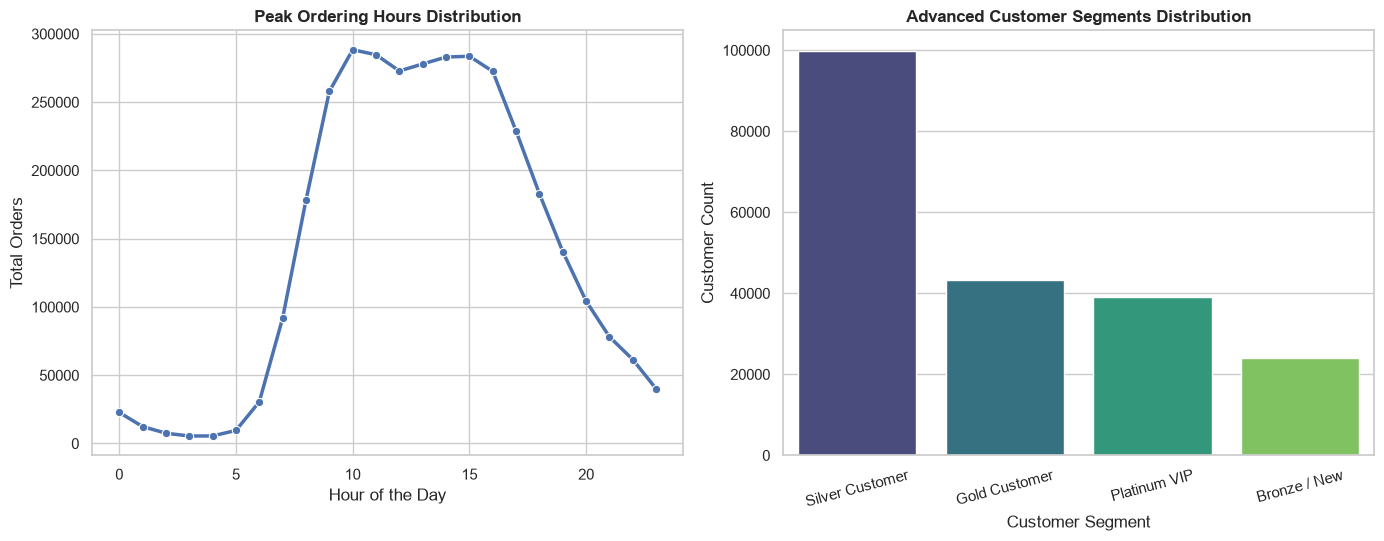

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد مظهر الرسوم البيانية
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# 1. رسوم بيانية لساعات ذروة الطلبات
plt.subplot(2, 2, 1)
peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

# 2. رسوم بيانية لشرائح العملاء المتقدمة
plt.subplot(2, 2, 2)
segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

<ipython-input-28-9c132f7590fc>:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


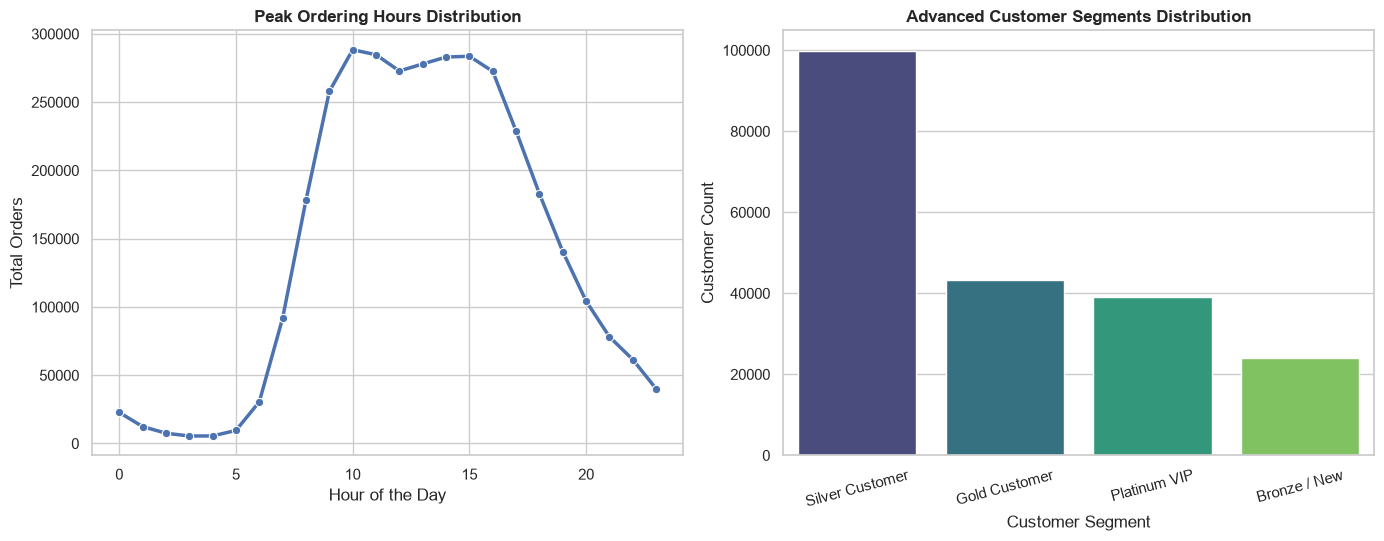

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد مظهر الرسوم البيانية
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# 1. رسوم بيانية لساعات ذروة الطلبات
plt.subplot(2, 2, 1)
peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

# 2. رسوم بيانية لشرائح العملاء المتقدمة
plt.subplot(2, 2, 2)
segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

<ipython-input-29-9c132f7590fc>:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


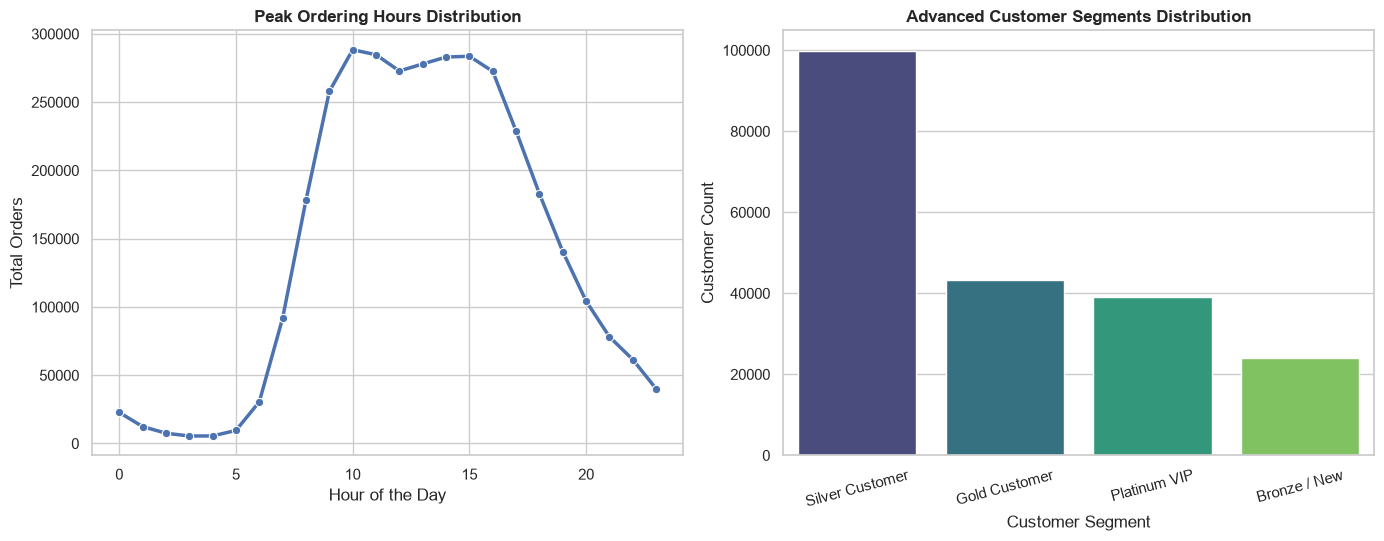

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد مظهر الرسوم البيانية
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# 1. رسوم بيانية لساعات ذروة الطلبات
plt.subplot(2, 2, 1)
peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

# 2. رسوم بيانية لشرائح العملاء المتقدمة
plt.subplot(2, 2, 2)
segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

<ipython-input-30-9c132f7590fc>:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


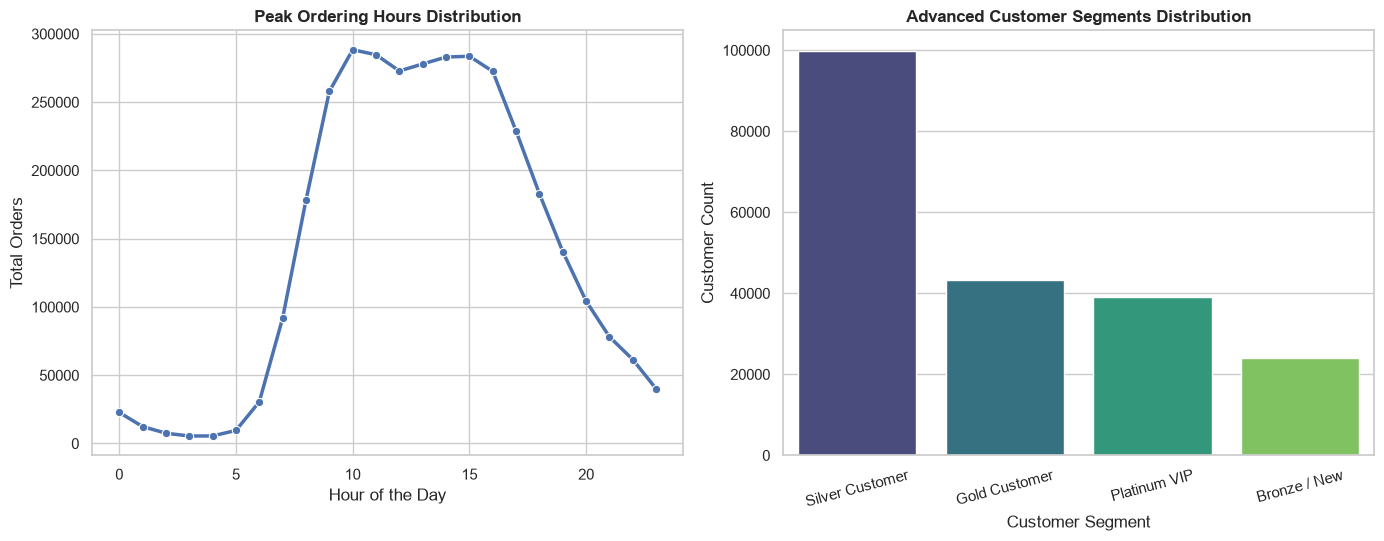

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد مظهر الرسوم البيانية
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# 1. رسوم بيانية لساعات ذروة الطلبات
plt.subplot(2, 2, 1)
peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

# 2. رسوم بيانية لشرائح العملاء المتقدمة
plt.subplot(2, 2, 2)
segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

<ipython-input-31-9c132f7590fc>:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


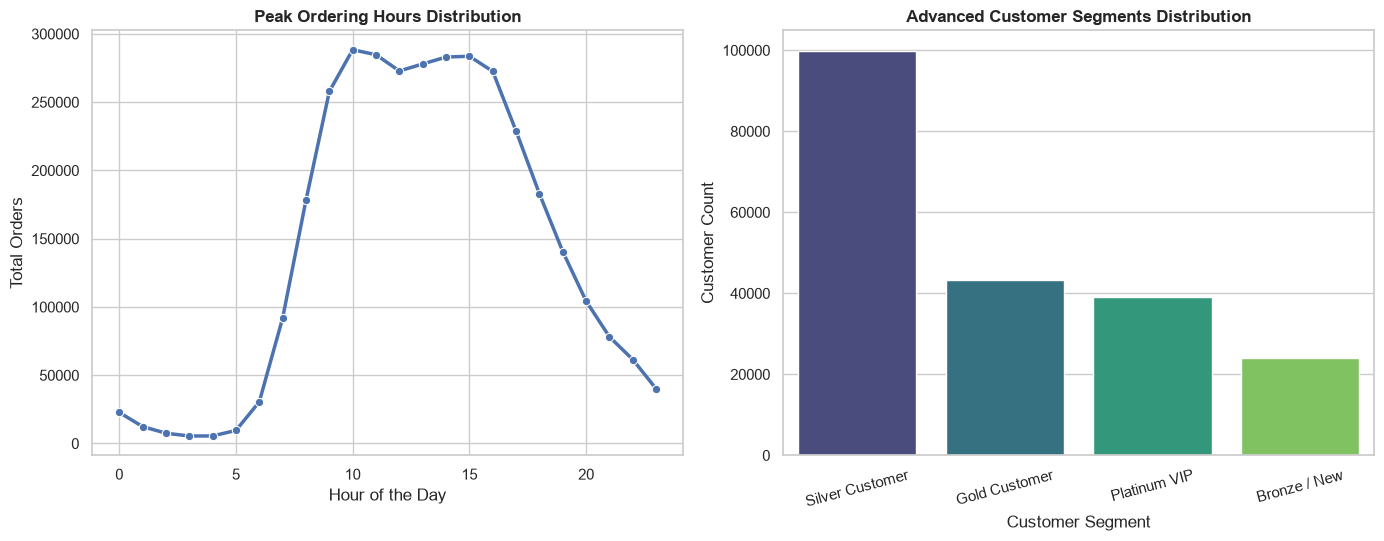

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد مظهر الرسوم البيانية
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# 1. رسوم بيانية لساعات ذروة الطلبات
plt.subplot(2, 2, 1)
peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

# 2. رسوم بيانية لشرائح العملاء المتقدمة
plt.subplot(2, 2, 2)
segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

<ipython-input-32-9c132f7590fc>:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


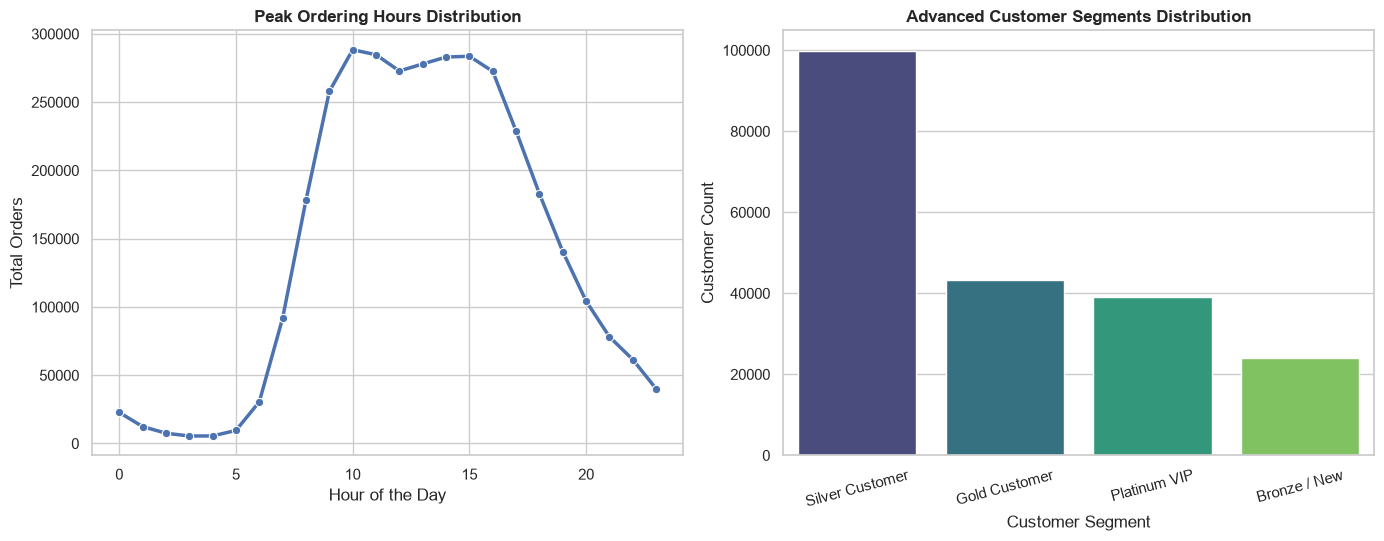

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد مظهر الرسوم البيانية
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# 1. رسوم بيانية لساعات ذروة الطلبات
plt.subplot(2, 2, 1)
peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

# 2. رسوم بيانية لشرائح العملاء المتقدمة
plt.subplot(2, 2, 2)
segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

<ipython-input-33-f2ecc0cafbbd>:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


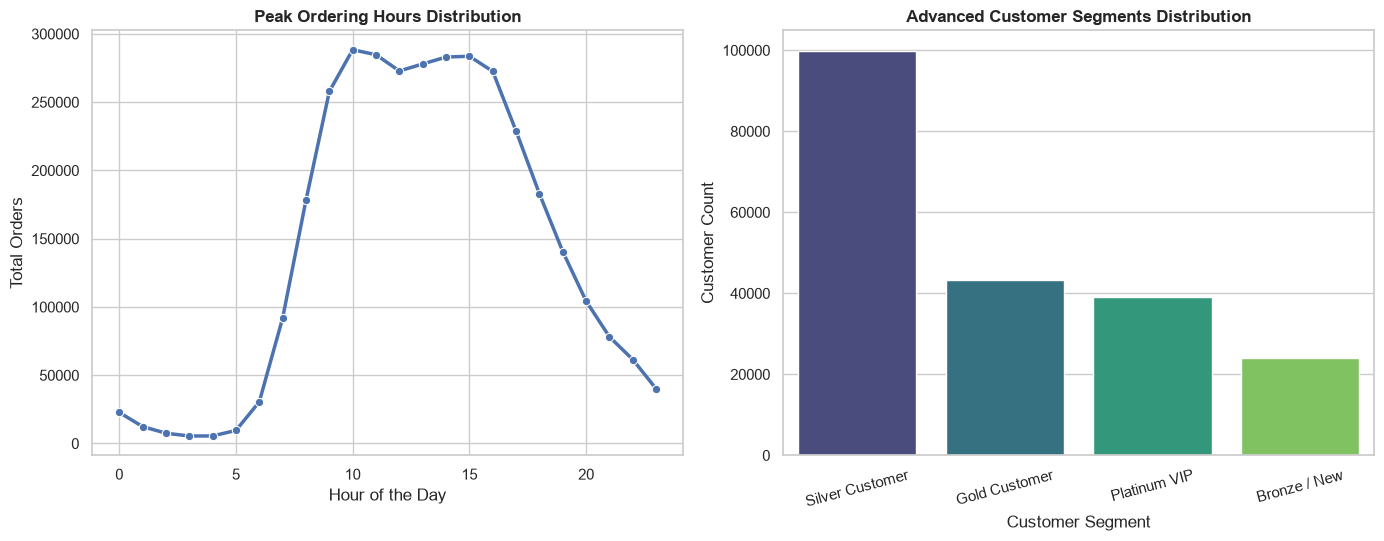

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

plt.subplot(2, 2, 2)
segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()

# حفظ الرسمة كصورة على الجهاز مباشرة
plt.savefig('eda_visualizations_report.png', dpi=300)
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. حساب متوسط حجم السلة وعدد المنتجات لكل طلب
basket_size_df = fact_order_products.groupby('order_id').agg(
    basket_size=('product_id', 'count')
).reset_index()

# 2. حساب معدل إعادة الشراء للمنتجات
product_reorder_stats = fact_order_products.groupby('product_id').agg(
    total_ordered=('order_id', 'count'),
    total_reordered=('reordered', 'sum')
).reset_index()
product_reorder_stats['reorder_rate'] = product_reorder_stats['total_reordered'] / product_reorder_stats['total_ordered']

# 3. حساب إجمالي الطلبات ومتوسط الأيام بين الطلبات لكل عميل
customer_metrics = orders.groupby('user_id').agg(
    total_orders=('order_id', 'count'),
    avg_days_between_orders=('days_since_prior_order', 'mean')
).reset_index()

# 4. تصنيف العملاء (Customer Segmentation / VIP vs Regular)
customer_metrics['customer_segment'] = np.where(
    customer_metrics['total_orders'] >= 15, 'VIP Customer', 'Regular Customer'
)

print("تم حساب جميع المقياس المتقدمة بنجاح في بايثون!")
print(customer_metrics.head())

تم حساب جميع المقياس المتقدمة بنجاح في بايثون!
   user_id  total_orders  avg_days_between_orders  customer_segment
0        1            11                19.000000  Regular Customer
1        2            15                16.285714      VIP Customer
2        3            13                12.000000  Regular Customer
3        4             6                17.000000  Regular Customer
4        5             5                11.500000  Regular Customer


In [ ]:
import pandas as pd
import numpy as np

# 1. حساب متوسط حجم السلة وعدد المنتجات لكل طلب
basket_size_df = fact_order_products.groupby('order_id').agg(
    basket_size=('product_id', 'count')
).reset_index()

# 2. حساب معدل إعادة الشراء للمنتجات
product_reorder_stats = fact_order_products.groupby('product_id').agg(
    total_ordered=('order_id', 'count'),
    total_reordered=('reordered', 'sum')
).reset_index()
product_reorder_stats['reorder_rate'] = product_reorder_stats['total_reordered'] / product_reorder_stats['total_ordered']

# 3. حساب إجمالي الطلبات ومتوسط الأيام بين الطلبات لكل عميل
customer_metrics = orders.groupby('user_id').agg(
    total_orders=('order_id', 'count'),
    avg_days_between_orders=('days_since_prior_order', 'mean')
).reset_index()

# 4. تصنيف العملاء (Customer Segmentation / VIP vs Regular)
customer_metrics['customer_segment'] = np.where(
    customer_metrics['total_orders'] >= 15, 'VIP Customer', 'Regular Customer'
)

print("تم حساب جميع المقياس المتقدمة بنجاح في بايثون!")
print(customer_metrics.head())

تم حساب جميع المقياس المتقدمة بنجاح في بايثون!
   user_id  total_orders  avg_days_between_orders  customer_segment
0        1            11                19.000000  Regular Customer
1        2            15                16.285714      VIP Customer
2        3            13                12.000000  Regular Customer
3        4             6                17.000000  Regular Customer
4        5             5                11.500000  Regular Customer


In [ ]:
display(customer_metrics.head(10))

,user_id,total_orders,avg_days_between_orders,customer_segment
0,1,11,19.000000,Regular Customer
1,2,15,16.285714,VIP Customer
2,3,13,12.000000,Regular Customer
3,4,6,17.000000,Regular Customer
4,5,5,11.500000,Regular Customer
5,6,4,13.333333,Regular Customer
6,7,21,10.450000,VIP Customer
7,8,4,23.333333,Regular Customer
8,9,4,22.000000,Regular Customer
9,10,6,21.800000,Regular Customer


<ipython-input-37-8d0ecedb8b14>:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


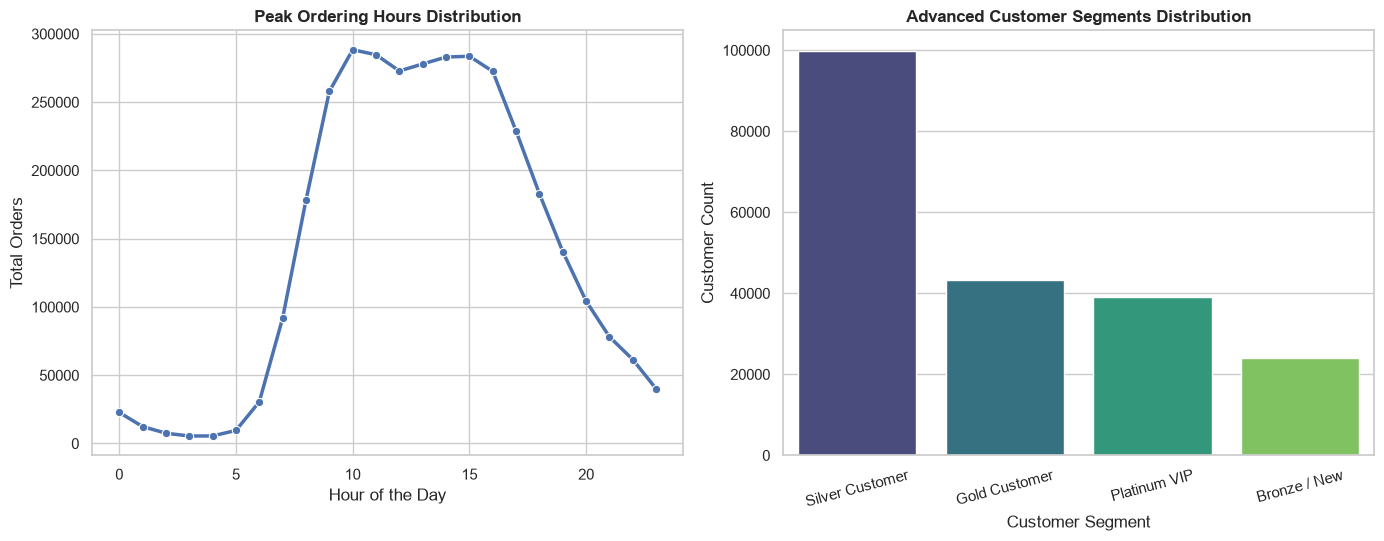

,user_id,total_orders,avg_days_between_orders,customer_segment
0,1,11,19.000000,Regular Customer
1,2,15,16.285714,VIP Customer
2,3,13,12.000000,Regular Customer
3,4,6,17.000000,Regular Customer
4,5,5,11.500000,Regular Customer
5,6,4,13.333333,Regular Customer
6,7,21,10.450000,VIP Customer
7,8,4,23.333333,Regular Customer
8,9,4,22.000000,Regular Customer
9,10,6,21.800000,Regular Customer


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

plt.subplot(2, 2, 2)
segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()

# حفظ الرسمة كصورة على الجهاز مباشرة
plt.savefig('eda_visualizations_report.png', dpi=300)
plt.show()
display(customer_metrics.head(10))

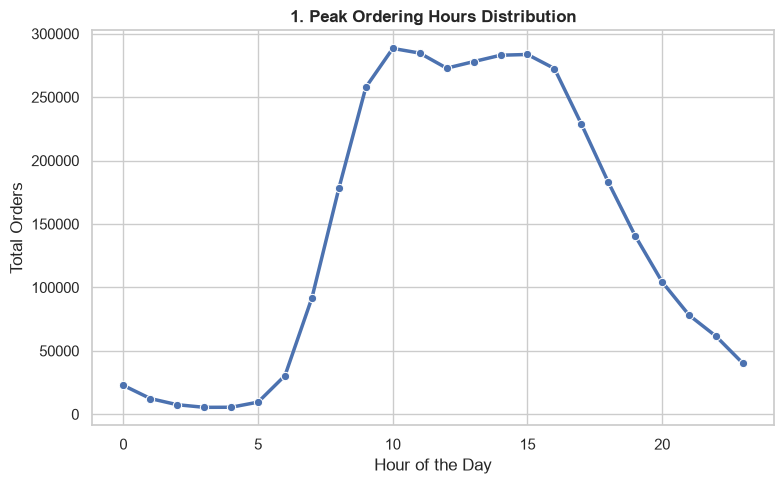

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

peak_plot_data = orders.groupby('order_hour_of_day')['order_id'].nunique().reset_index()
sns.lineplot(data=peak_plot_data, x='order_hour_of_day', y='order_id', marker='o', color='b', linewidth=2.5)
plt.title('1. Peak Ordering Hours Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Orders')

plt.tight_layout()
plt.savefig('eda_plot_1.png', dpi=300)
plt.show()

<ipython-input-39-f3dfc5f18156>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')


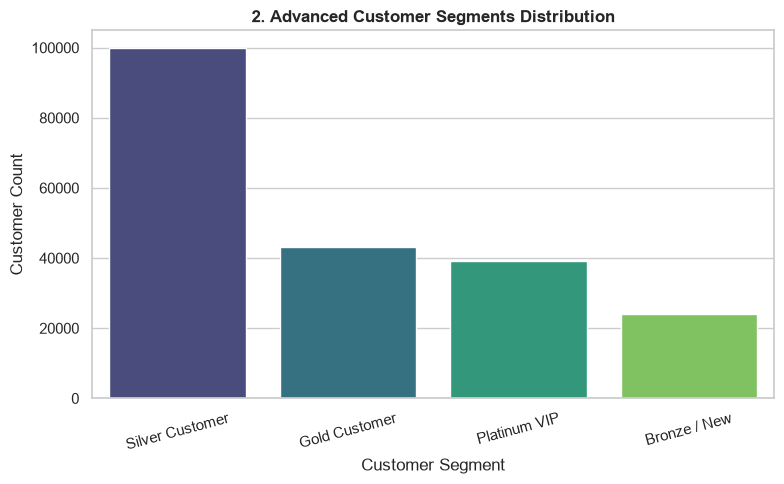

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

segment_plot_data = rfm_advanced['customer_segment_advanced'].value_counts().reset_index()
sns.barplot(data=segment_plot_data, x='customer_segment_advanced', y='count', palette='viridis')
plt.title('2. Advanced Customer Segments Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Count')
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig('eda_plot_2.png', dpi=300)
plt.show()

<ipython-input-40-7ae3ff2e521c>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dow_plot_data, x='order_dow', y='order_id', palette='crest')


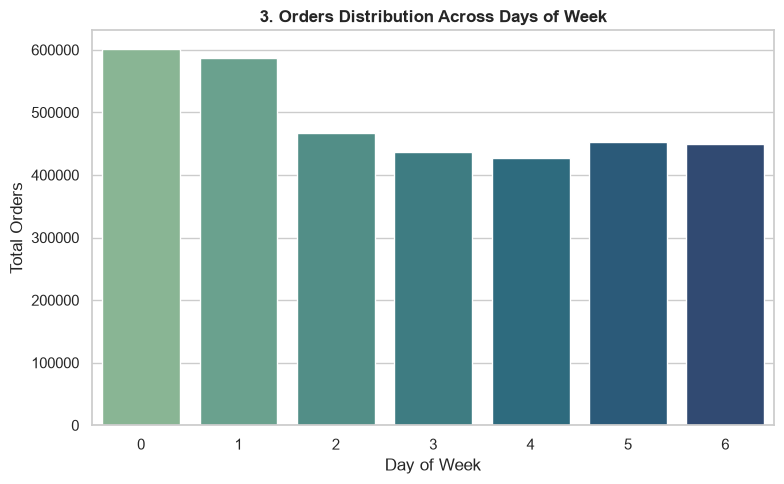

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

dow_plot_data = orders.groupby('order_dow')['order_id'].nunique().reset_index()
sns.barplot(data=dow_plot_data, x='order_dow', y='order_id', palette='crest')
plt.title('3. Orders Distribution Across Days of Week', fontsize=12, fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Total Orders')

plt.tight_layout()
plt.savefig('eda_plot_3.png', dpi=300)
plt.show()

<ipython-input-41-95957cfcfc2c>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=basket_plot_data, x='basket_size', y='count', palette='magma')


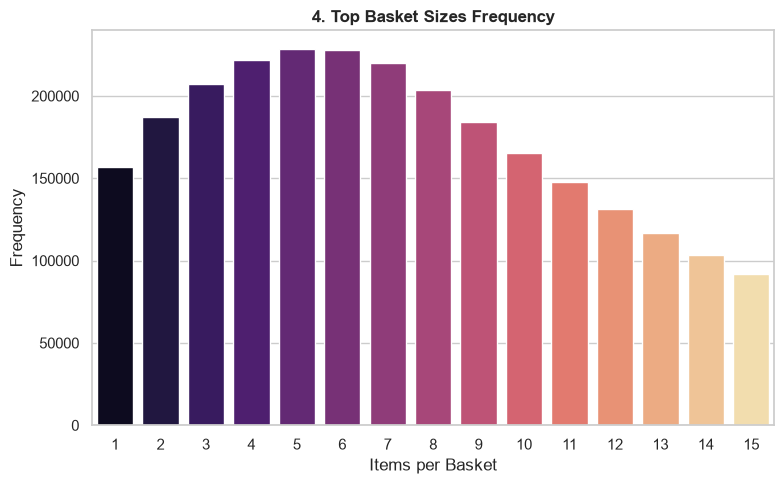

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

basket_plot_data = basket_size_df['basket_size'].value_counts().head(15).reset_index()
sns.barplot(data=basket_plot_data, x='basket_size', y='count', palette='magma')
plt.title('4. Top Basket Sizes Frequency', fontsize=12, fontweight='bold')
plt.xlabel('Items per Basket')
plt.ylabel('Frequency')

plt.tight_layout()
plt.savefig('eda_plot_4.png', dpi=300)
plt.show()

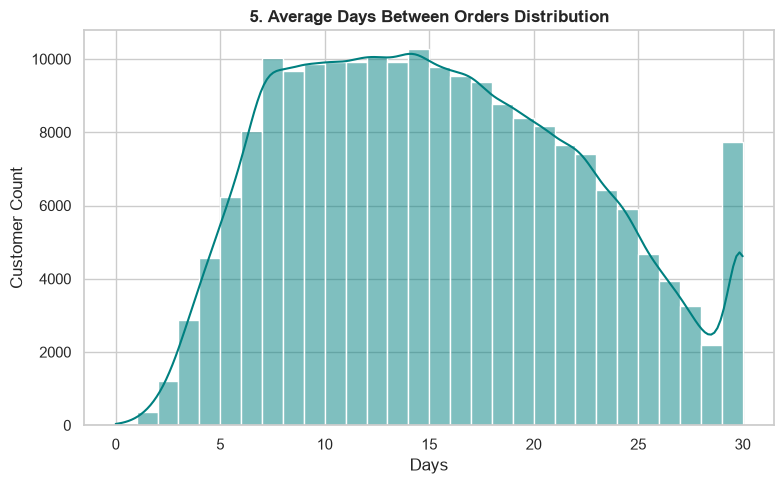

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

sns.histplot(data=customer_metrics, x='avg_days_between_orders', bins=30, kde=True, color='teal')
plt.title('5. Average Days Between Orders Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Days')
plt.ylabel('Customer Count')

plt.tight_layout()
plt.savefig('eda_plot_5.png', dpi=300)
plt.show()

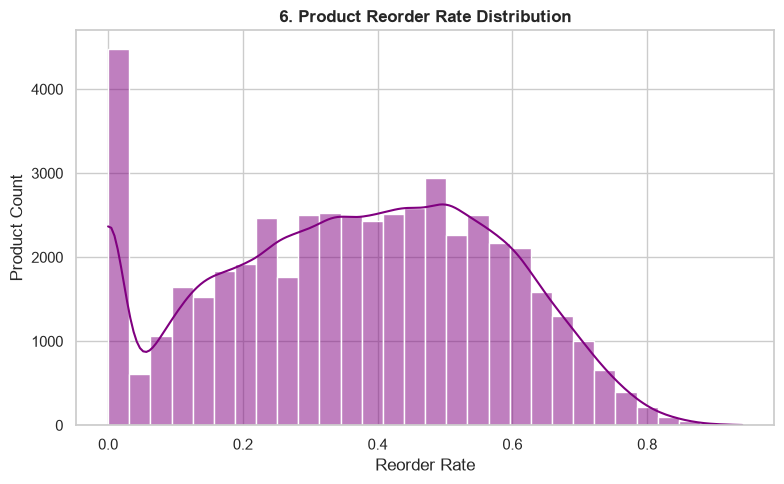

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

sns.histplot(data=product_reorder_stats, x='reorder_rate', bins=30, kde=True, color='purple')
plt.title('6. Product Reorder Rate Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Reorder Rate')
plt.ylabel('Product Count')

plt.tight_layout()
plt.savefig('eda_plot_6.png', dpi=300)
plt.show()

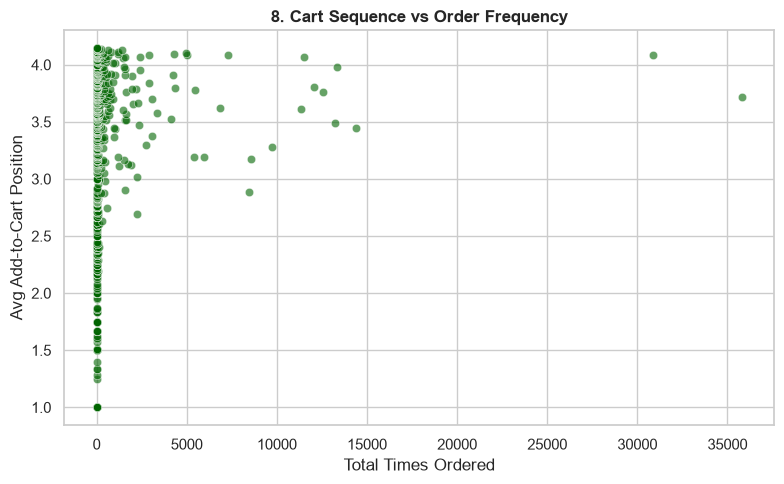

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

sns.scatterplot(data=cart_sequence_df.head(1000), x='total_times_ordered', y='avg_add_to_cart_sequence_order', alpha=0.6, color='darkgreen')
plt.title('8. Cart Sequence vs Order Frequency', fontsize=12, fontweight='bold')
plt.xlabel('Total Times Ordered')
plt.ylabel('Avg Add-to-Cart Position')

plt.tight_layout()
plt.savefig('eda_plot_8.png', dpi=300)
plt.show()

In [ ]:
import os
import pandas as pd

output_dir = 'parquet_exports'
os.makedirs(output_dir, exist_ok=True)

tables_to_export = {
    'orders': orders,
    'fact_order_products': fact_order_products,
    'products': products,
    'basket_size_df': basket_size_df,
    'product_reorder_stats': product_reorder_stats,
    'customer_metrics': customer_metrics,
    'diversity_df': diversity_df,
    'rfm_advanced': rfm_advanced
}

for name, df in tables_to_export.items():
    file_path = os.path.join(output_dir, f'{name}.parquet')
    try:
        df.to_parquet(file_path, index=False, engine='pyarrow')
        print(f"Successfully exported: {name}.parquet")
    except Exception as e:
        print(f"Failed to export {name}: {e}")

print("\nAll tables have been successfully exported to Parquet format inside 'parquet_exports' folder!")

NameError: name 'diversity_df' is not defined

In [ ]:
import os
import pandas as pd

output_dir = 'parquet_exports'
os.makedirs(output_dir, exist_ok=True)

tables_to_export = {
    'orders': orders,
    'fact_order_products': fact_order_products,
    'products': products,
    'basket_size_df': basket_size_df,
    'product_reorder_stats': product_reorder_stats,
    'customer_metrics': customer_metrics,
    'rfm_advanced': rfm_advanced
}

for name, df in tables_to_export.items():
    file_path = os.path.join(output_dir, f'{name}.parquet')
    try:
        df.to_parquet(file_path, index=False, engine='pyarrow')
        print(f"Successfully exported: {name}.parquet")
    except Exception as e:
        print(f"Failed to export {name}: {e}")

print("\nAll tables have been successfully exported to Parquet format inside 'parquet_exports' folder!")

Successfully exported: orders.parquet
Successfully exported: fact_order_products.parquet
Failed to export products: 'list' object has no attribute 'to_parquet'
Successfully exported: basket_size_df.parquet
Successfully exported: product_reorder_stats.parquet
Successfully exported: customer_metrics.parquet
Successfully exported: rfm_advanced.parquet

All tables have been successfully exported to Parquet format inside 'parquet_exports' folder!


In [ ]:
import os
import pandas as pd

output_dir = 'parquet_exports'
os.makedirs(output_dir, exist_ok=True)

tables_to_export = {
    'orders': orders,
    'fact_order_products': fact_order_products,
    'products': products,
    'aisles': aisles,
    'departments': departments,
    'basket_size_df': basket_size_df,
    'product_reorder_stats': product_reorder_stats,
    'customer_metrics': customer_metrics,
    'rfm_advanced': rfm_advanced
}

for name, df in tables_to_export.items():
    file_path = os.path.join(output_dir, f'{name}.parquet')
    try:
        df.to_parquet(file_path, index=False, engine='pyarrow')
        print(f"Successfully exported: {name}.parquet")
    except Exception as e:
        print(f"Failed to export {name}: {e}")

print("\nAll schema tables have been successfully exported to Parquet format inside 'parquet_exports' folder!")

Successfully exported: orders.parquet
Successfully exported: fact_order_products.parquet
Failed to export products: 'list' object has no attribute 'to_parquet'
Successfully exported: aisles.parquet
Successfully exported: departments.parquet
Successfully exported: basket_size_df.parquet
Successfully exported: product_reorder_stats.parquet
Successfully exported: customer_metrics.parquet
Successfully exported: rfm_advanced.parquet

All schema tables have been successfully exported to Parquet format inside 'parquet_exports' folder!


In [ ]:
# Optional additional tables for advanced analysis or reporting
tables_to_export.update({
    'cart_sequence_df': cart_sequence_df,
    'departments': departments,
    'aisles': aisles
})

for name, df in tables_to_export.items():
    file_path = os.path.join(output_dir, f'{name}.parquet')
    try:
        df.to_parquet(file_path, index=False, engine='pyarrow')
        print(f"Successfully exported: {name}.parquet")
    except Exception as e:
        print(f"Failed to export {name}: {e}")

print("\nAll required schema and analytical tables are successfully exported!")

Successfully exported: orders.parquet
Successfully exported: fact_order_products.parquet
Failed to export products: 'list' object has no attribute 'to_parquet'
Successfully exported: aisles.parquet
Successfully exported: departments.parquet
Successfully exported: basket_size_df.parquet
Successfully exported: product_reorder_stats.parquet
Successfully exported: customer_metrics.parquet
Successfully exported: rfm_advanced.parquet
Successfully exported: cart_sequence_df.parquet

All required schema and analytical tables are successfully exported!
